Ali Khabazian - 402416066

"Advanced quantum mechanic 1, TA project"

>> Based on details of the question we have a double well which included of an infinite well potential and a barrier in the middle of that well. we assume that both of them are symmetric. so for x between -a and +a we have the infinite well and in between of that erea, the barrier is located in between -b to +b. we also know that particles can go through the barrier and quantum tunneling made wave function continued on the right side. it means we can assume that E is lower than V_0. (E < v_0)

>>Now with the help of schrodinger equation we can wrtie its wave functions for all three parts; in the first and third part, we use of sine and cosine form for wave function because we know that in both side we have a oscillating waves and for the central one we have to write it with the help of exponential functions. Here it is the potential of each part (1) and the wave function equations (2)



(1) V(x) =
\begin{cases} 
0, & -a \leq x \leq -b \\
V_0, & -b \leq x \leq +b \\
0, & +b \leq x \leq +a \\
+\infty, & \text{otherwise}
\end{cases}



(2) Psi (x) =

\begin{array}{ll}
A\sin (kx) + B\cos (kx), & -a \leq x \leq -b \\
C e^{-k'x} + D e^{k'x}, & -b \leq x \leq +b \\
E\sin (kx) + F\cos (kx), & +b \leq x \leq +a \\
0 &                |x| \geq a
\end{array}



>> in this part we have to find k and k_perime which means if we solve the second order differential equation, i mean schrodinger eq, we can reach them. and based the concluded realtions we can write down energy formula for both part (quantum tunneling and oscillating ones). here it is its formulas:



\begin{gathered}
  k^2 = \frac{2mE}{\hbar^2} \\
  
  k'^2 = \frac{2m}{\hbar^2} (V_0 - E)
\end{gathered}



>> so to reach the formulas for energy, we have to simplify the wave functions based on boundary conditions. at the fisrt we know that in near of infinte well, x=+a,-a, the psi is equal to zero. and the cosine parts will be disappeared. and in the next stage we have to consider Continuity of the derivative of wave functions function on x=+b, -b. after its calculation, whcih you can see them in the adhesive note, we will know that C, D coefficents have to be equal for even eigenfunctions and the result of that tells us that A have to be equal to negetive E. and for odd eigenfunction we have C=-E and A=E

>> if we put n=1,2 in 4 formula, we can wite its first and second energy level

(3) Psi (x) =

\begin{array}{ll}
A\sin k(x+a), & -a \leq x \leq -b \\
C e^{-k'x} + D e^{k'x}, & -b \leq x \leq +b \\
E\sin k(x-a), & +b \leq x \leq +a \\
0  &                |x| \geq a
\end{array}


(4)

$$E = \frac{{{\hbar ^2}{n^2}{\pi ^2}}}{{2m}{a^2}}$$

Part 1: plot of wave functions, ground and first excited energy states

Ground state energy (even): 2.2950
First excited state energy (odd): 8.1371


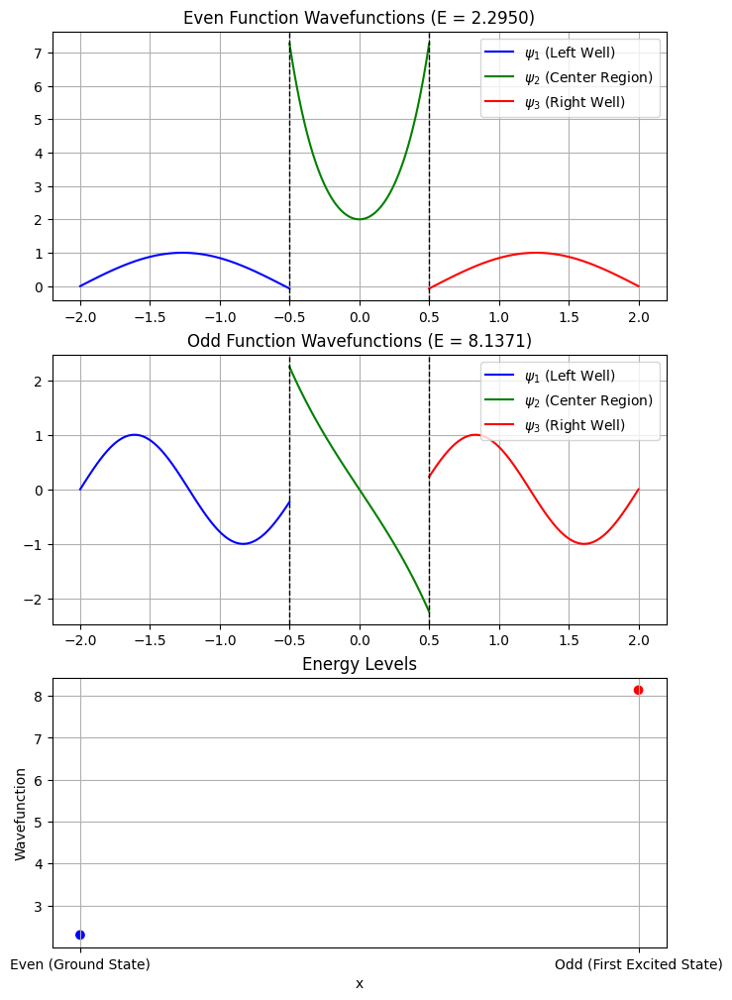

In [11]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve

# parameters
a = 2    
b = 0.5  
V0 = 10  # Barrier height
m = 1    # Mass
hbar = 1 

# functions for energy quantization conditions
def even_quantization(E):
    k = np.sqrt(2 * m * E) / hbar ** 2
    kaprime = np.sqrt(2 * m * (V0 - E)) / hbar ** 2
    return k * np.tan(k * b) - kaprime

def odd_quantization(E):
    k = np.sqrt(2 * m * E) / hbar ** 2
    kaprime = np.sqrt(2 * m * (V0 - E)) / hbar ** 2
    return -k / np.tan(k * b) - kaprime  # Replacing np.cot with 1/np.tan because of error in np for cot

# Solve for energy levels numerically
E_initial_guess = [1, 4]  # Initial guesses for first two levels
E_even = fsolve(even_quantization, E_initial_guess[0])[0]
E_odd = fsolve(odd_quantization, E_initial_guess[1])[0]

print(f"Ground state energy (even): {E_even:.4f}")
print(f"First excited state energy (odd): {E_odd:.4f}")


kaprime_even = np.sqrt(2 * m * (V0 - E_even)) / hbar ** 2
kaprime_odd = np.sqrt(2 * m * (V0 - E_odd)) / hbar ** 2

# central part formula
x_center = np.linspace(-b, b, 100)
psi2_even_formula = np.exp(-kaprime_even * x_center) + np.exp(kaprime_even * x_center)
psi2_odd_formula = np.exp(-kaprime_odd * x_center) - np.exp(kaprime_odd * x_center)

# Even function 
c = 1  # Coefficient for exponential decay
d = 1  # Normalization constant
c_even = -d
k_even = np.sqrt(2 * m * E_even) / hbar ** 2

psi2_even = c * psi2_even_formula
psi1_even = d * np.sin(k_even * (np.linspace(-a, -b, 100) + a))
psi3_even = c_even * np.sin(k_even * (np.linspace(b, a, 100) - a))

# Odd function 
c_odd = d
k_odd = np.sqrt(2 * m * E_odd) / hbar ** 2

psi2_odd = c * psi2_odd_formula
psi1_odd = d * np.sin(k_odd * (np.linspace(-a, -b, 100) + a))
psi3_odd = c_odd * np.sin(k_odd * (np.linspace(b, a, 100) - a))

# Plot
fig, ax = plt.subplots(3, 1, figsize=(8, 12))

# Even function plot
ax[0].plot(np.linspace(-a, -b, 100), psi1_even, label="$\psi_1$ (Left Well)", color='b')
ax[0].plot(np.linspace(-b, b, 100), psi2_even, label="$\psi_2$ (Center Region)", color='g')
ax[0].plot(np.linspace(b, a, 100), psi3_even, label="$\psi_3$ (Right Well)", color='r')
ax[0].axvline(-b, color='k', linestyle='--', linewidth=1)
ax[0].axvline(b, color='k', linestyle='--', linewidth=1)
ax[0].set_title(f"Even Function Wavefunctions (E = {E_even:.4f})")
ax[0].legend()
ax[0].grid()

# Odd function plot
ax[1].plot(np.linspace(-a, -b, 100), psi1_odd, label="$\psi_1$ (Left Well)", color='b')
ax[1].plot(np.linspace(-b, b, 100), psi2_odd, label="$\psi_2$ (Center Region)", color='g')
ax[1].plot(np.linspace(b, a, 100), psi3_odd, label="$\psi_3$ (Right Well)", color='r')
ax[1].axvline(-b, color='k', linestyle='--', linewidth=1)
ax[1].axvline(b, color='k', linestyle='--', linewidth=1)
ax[1].set_title(f"Odd Function Wavefunctions (E = {E_odd:.4f})")
ax[1].legend()
ax[1].grid()

# Energy level plot
energy_levels = [E_even, E_odd]
labels = ["Even (Ground State)", "Odd (First Excited State)"]
ax[2].scatter(labels, energy_levels, color=['b', 'r'])
ax[2].set_title("Energy Levels")
ax[2].set_ylabel("Energy")
ax[2].grid()

plt.xlabel("x")
plt.ylabel("Wavefunction")
plt.show()


Part 2: combining all wave function and plotting its dynamic evoultion 

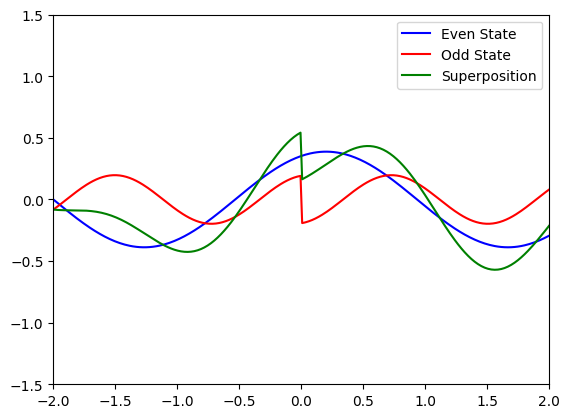

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from scipy.optimize import fsolve
from IPython.display import HTML

# Parameters
a = 2    
b = 0.5  
V0 = 10  # Barrier height 
m = 1    # Mass
hbar = 1 

# Functions for energy quantization conditions
def even_quantization(E):
    k = np.sqrt(2 * m * E) / hbar ** 2
    kaprime = np.sqrt(2 * m * (V0 - E)) / hbar ** 2
    return k * np.tan(k * b) - kaprime

def odd_quantization(E):
    k = np.sqrt(2 * m * E) / hbar ** 2
    kaprime = np.sqrt(2 * m * (V0 - E)) / hbar ** 2
    return -k / np.tan(k * b) - kaprime  

# Solve for energy levels numerically
E_even = fsolve(even_quantization, 1)[0]
E_odd = fsolve(odd_quantization, 4)[0]

# Define spatial domain
x = np.linspace(-a, a, 300)
k_even = np.sqrt(2 * m * E_even) / hbar ** 2
k_odd = np.sqrt(2 * m * E_odd) / hbar ** 2

# Wavefunctions at t = 0
psi_even_x0 = np.sin(k_even * (x + a))
psi_odd_x0 = np.sign(x) * np.sin(k_odd * (np.abs(x) + a))

# Normalize wavefunctions
psi_even_x0 /= np.max(np.abs(psi_even_x0))
psi_odd_x0 /= np.max(np.abs(psi_odd_x0))

# Setup animation
fig, ax = plt.subplots()
line_even, = ax.plot([], [], 'b-', label='Even State')
line_odd, = ax.plot([], [], 'r-', label='Odd State')
line_both, = ax.plot([], [], 'g-', label='Superposition')

ax.set_xlim(-a, a)
ax.set_ylim(-1.5, 1.5)
ax.legend()

def init():
    line_even.set_data([], [])
    line_odd.set_data([], [])
    line_both.set_data([], [])
    return line_even, line_odd, line_both

def animate(t):
    psi_t_even = psi_even_x0 * np.cos(E_even * t / hbar)
    psi_t_odd = psi_odd_x0 * np.cos(E_odd * t / hbar) # we use of cosine because numpy cant plot complex number
    psi_t_both = psi_t_even + psi_t_odd
    
    line_even.set_data(x, psi_t_even)
    line_odd.set_data(x, psi_t_odd)
    line_both.set_data(x, psi_t_both)


    return line_even, line_odd, line_both

ani = animation.FuncAnimation(fig, animate, frames=200, init_func=init, interval=25, blit=True)
HTML(ani.to_jshtml())

